# Global model — kết quả chi tiết

`train_global.py`: LightGBM tune bằng Optuna TPE (vòng trong GroupKFold theo ô) trên 5 fold ngoài theo ô dùng chung, hai biến thể `original/` (chỉ x) và `st/` (+ 9 biến không gian/thời gian của train_v3 cũ). So sánh với các mô hình khác: `../compare_models.ipynb`.

## 0. Thiết lập

In [1]:
%matplotlib inline
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook'); plt.rcParams['figure.dpi'] = 110
MODEL_DIR = Path.cwd().parents[0]                        # pm25_map/model
sys.path.insert(0, str(MODEL_DIR))
import _data as D, _results as R
frame = D.build_frame(); cells = R.cell_table(frame)
GD = MODEL_DIR / 'global_model'
runs = {}
for v in ('original', 'st'):
    p = GD / v / 'metrics.json'
    if p.exists(): runs[v] = json.loads(p.read_text())
print('đã có:', list(runs))

đã có: ['original', 'st']


## 1. Chỉ số gộp và theo fold

In [2]:
rows = []
for v, s in runs.items():
    rows.append(dict(variant=v, **{k: s['pooled'][k] for k in ('N', 'R2', 'R2_paper', 'RMSE', 'MAE', 'RPE', 'slope')},
                     **{f'R2_f{k}': s['per_fold'][k]['R2'] for k in sorted(s['per_fold'])}))
pd.DataFrame(rows).set_index('variant').round(3) if rows else print('chưa có metrics.json nào')

,N,R2,R2_paper,RMSE,MAE,RPE,slope,R2_f0,R2_f1,R2_f2,R2_f3,R2_f4
variant,,,,,,,,,,,,
original,46377,0.488,0.492,16.317,11.014,62.747,0.537,0.404,0.571,0.491,0.569,0.296
st,46377,0.570,0.574,14.942,9.839,57.459,0.620,0.458,0.719,0.522,0.659,0.481


## 2. Tham số Optuna từng fold và mô hình triển khai

In [3]:
for v in ('original', 'st'):
    s = runs.get(v)
    if not s: continue
    t = pd.DataFrame({k: {**f['best_params'], 'inner_cv_r2': f['inner_cv_r2'], 'test_R2': f['R2']} for k, f in s['per_fold'].items()}).T
    print(f'── {v}'); display(t.round(4))
    if 'final_model' in s:
        print('mô hình triển khai (tune trên toàn bộ):', {k: (round(x, 4) if isinstance(x, float) else x) for k, x in s['final_model']['params'].items() if k in t.columns}, '· R² CV =', round(s['final_model']['cv_r2_all'], 3))

── original


,bagging_freq,num_leaves,min_data_in_leaf,learning_rate,feature_fraction,bagging_fraction,inner_cv_r2,test_R2
0,5.0,297.0,20.0,0.0201,0.7441,0.7167,0.5372,0.4040
1,5.0,21.0,58.0,0.0051,0.7854,0.6345,0.4253,0.5707
2,5.0,80.0,38.0,0.0341,0.7932,0.8021,0.4991,0.4915
3,5.0,425.0,47.0,0.0159,0.8079,0.6451,0.4886,0.5694
4,5.0,303.0,34.0,0.0236,0.6698,0.8068,0.5616,0.2960


mô hình triển khai (tune trên toàn bộ): {'bagging_freq': 5, 'num_leaves': 377, 'min_data_in_leaf': 20, 'learning_rate': 0.0058, 'feature_fraction': 0.6507, 'bagging_fraction': 0.6084} · R² CV = 0.47
── st


,bagging_freq,num_leaves,min_data_in_leaf,learning_rate,feature_fraction,bagging_fraction,inner_cv_r2,test_R2
0,5.0,75.0,25.0,0.0779,0.8499,0.9044,0.5825,0.4577
1,5.0,145.0,94.0,0.0545,0.6019,0.7686,0.5452,0.7191
2,5.0,91.0,24.0,0.0180,0.6386,0.6509,0.6125,0.5218
3,5.0,357.0,29.0,0.0093,0.6206,0.7763,0.5583,0.6586
4,5.0,393.0,30.0,0.0244,0.6012,0.9622,0.6003,0.4806


mô hình triển khai (tune trên toàn bộ): {'bagging_freq': 5, 'num_leaves': 335, 'min_data_in_leaf': 76, 'learning_rate': 0.0251, 'feature_fraction': 0.6819, 'bagging_fraction': 0.9332} · R² CV = 0.579


## 3. Độ quan trọng biến (% gain, TB qua 5 fold)

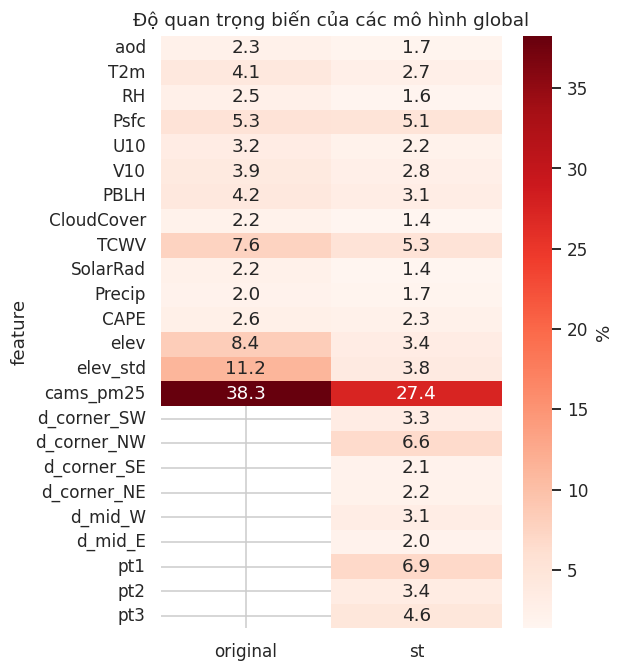

In [4]:
fi = {}
for v in runs:
    p = GD / v / 'feature_importance.csv'
    if p.exists(): fi[v] = pd.read_csv(p).set_index('feature').importance_pct
if fi:
    T = pd.DataFrame(fi).reindex(D.X_VARS + D.ST_VARS)
    fig, ax = plt.subplots(figsize=(5, 7))
    sns.heatmap(T, annot=True, fmt='.1f', cmap='Reds', ax=ax, cbar_kws={'label': '%'})
    ax.set_title('Độ quan trọng biến của các mô hình global'); plt.show()

## 4. original ↔ -st: biến không gian/thời gian giúp bao nhiêu

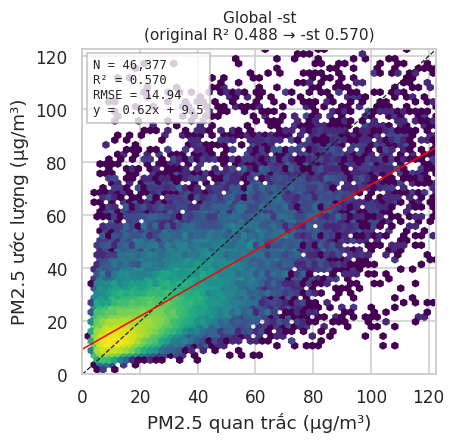

In [5]:
preds = R.load_global()
pairs = [('Global', 'Global -st')] if {'Global', 'Global -st'} <= set(preds) else []
if pairs:
    J = R.joined(preds, frame, [n for p in pairs for n in p])
    fig, axes = plt.subplots(1, len(pairs), figsize=(4.3 * len(pairs), 4.2), squeeze=False)
    for ax, (a, b) in zip(axes.ravel(), pairs):
        ra, rb = D.metrics(J[D.PM], J[a]), D.metrics(J[D.PM], J[b])
        R.density(ax, J[D.PM].values, J[b].values, f'{b}\n(original R² {ra["R2"]:.3f} → -st {rb["R2"]:.3f})')
    plt.tight_layout(); plt.show()

## 5. Nhận xét (cập nhật 27/10/2026)

**Chỉ số gộp** trên 5 fold theo ô (46.377 ô–ngày, 80 ô):

| Biến thể | R² | RMSE | Độ dốc | R² theo fold |
|---|---|---|---|---|
| `original` (15 biến x) | 0,488 | 16,32 | 0,54 | 0,40 / 0,57 / 0,49 / 0,57 / 0,30 |
| `st` (+ 9 biến không gian/thời gian) | **0,570** | **14,94** | 0,62 | 0,46 / 0,72 / 0,52 / 0,66 / 0,48 |

- **Bản `-st` tốt hơn rõ** (+0,08 R², RMSE −8%), giống Supplementary Table 1 của Li et al. 2024. Khoảng cách tới góc khung, mùa (pt1/pt2) và năm (pt3) cho mô hình biết nơi và lúc mà 15 biến x chưa nói hết.
- **Fold 4 luôn khó nhất, fold 1 dễ nhất.** Kết quả phụ thuộc nhiều vào việc ô nào rơi vào tập test.
- **R² vòng trong (0,43–0,61) không dự báo được R² test.** Ví dụ fold 4 bản `original`: R² vòng trong 0,56 nhưng R² test chỉ 0,30. Với 80 ô, ước lượng chất lượng từ vòng trong còn rất nhiễu.
- **Tham số tối ưu đổi mạnh giữa các fold** (num_leaves 21–425, lr 0,005–0,08). Không có một vùng tham số ổn định.
- **Độ quan trọng biến**
  - CAMS PM2.5 chiếm phần lớn: mô hình chủ yếu đang hiệu chỉnh CAMS.
  - DEM bị giảm vai trò ở bản `-st` khi đã có biến vị trí.
  - AOD chỉ chiếm vài %.
- **Mô hình triển khai:** `st/model.txt` (num_leaves 335, min_data_in_leaf 76, lr 0,025, R² CV 0,579). Đây là ứng viên tốt nhất để vẽ bản đồ ngày.